In [41]:
import random
import math
from collections import namedtuple, deque
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

In [ ]:
# class MarkovianHouseSellingEnvContinuous:
#     def __init__(self, s0=50.0, cost=10.0, T=10, mu=0.0, sigma=5.0):
#         self.s0 = float(s0)
#         self.cost = float(cost)
#         self.T = int(T)
#         self.mu = float(mu)
#         self.sigma = float(sigma)
#         self.reset()

#     def reset(self):
#         self.s = self.s0
#         self.t = 0
#         self.stops_left = 2
#         return np.array([self.s, self.t / self.T, self.stops_left], dtype=np.float32)

#     def step(self, action: int):
#         """
#         action: 0 (hold) or 1 (stop)
#         returns: (next_state, reward, done)
#         """
#         reward = 0.0
#         done = False

#         # Execute stopping action if allowed
#         if action == 1 and self.stops_left > 0:
#             reward = self.s if self.stops_left == 1 else self.s - self.cost
#             self.stops_left -= 1

#         # Episode ends if no time or no stops left
#         if self.t >= self.T - 1 or self.stops_left == 0:
#             done = True
#             return np.array([self.s, self.t / self.T, self.stops_left], dtype=np.float32), reward, done

#         # Otherwise, advance state
#         self.t += 1
#         self.s += np.random.normal(self.mu, self.sigma)
#         return np.array([self.s, self.t / self.T, self.stops_left], dtype=np.float32), reward, False

#     @property
#     def actions(self):
#         return [0, 1]  # 0 = hold, 1 = stop
    


In [43]:
Transition = namedtuple("Transition", ["state", "action", "reward", "next_state", "done"])

class ReplayBuffer:
    def __init__(self, capacity: int):
        self.buffer = deque(maxlen=capacity)

    def push(self, *args):
        self.buffer.append(Transition(*args))

    def sample(self, batch_size: int):
        batch = random.sample(self.buffer, batch_size)
        return Transition(*zip(*batch))

    def __len__(self):
        return len(self.buffer)

In [44]:
class QNetwork(nn.Module):
    def __init__(self, input_dim: int, output_dim: int, hidden_dim: int = 128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, output_dim)
        )


    def forward(self, x):
        return self.net(x)

In [ ]:
class DQNAgent:
    def __init__(
        self,
        env,
        lr: float = 1e-3,
        state_dim: int = 3,
        gamma: float = 1,
        epsilon_start: float = 1.0,
        epsilon_end: float = 0.5,
        epsilon_decay: float = 500,
        buffer_size: int = 10000,
        batch_size: int = 256,
        target_update_freq: int = 20,
        hidden_dim: int = 128
    ):
        self.env = env
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

        self.state_dim = state_dim
        self.action_dim = len(env.actions)

        self.q_net = QNetwork(self.state_dim, self.action_dim, hidden_dim).to(self.device)
        self.target_net = QNetwork(self.state_dim, self.action_dim, hidden_dim).to(self.device)
        self.target_net.load_state_dict(self.q_net.state_dict())
        self.target_net.eval()

        self.optimizer = optim.Adam(self.q_net.parameters(), lr=lr)
        self.replay_buffer = ReplayBuffer(buffer_size)

        self.gamma = gamma
        self.epsilon = epsilon_start
        self.epsilon_end = epsilon_end
        self.epsilon_decay = epsilon_decay
        self.batch_size = batch_size
        self.target_update_freq = target_update_freq

        self.steps_done = 0
        self.episode_rewards = []
        self.episode_regret = []


        # --- NEW: Create and pre-populate the "Known Q-Values" table ---
        # Initialize a table with NaNs to signify 'unknown' values
        self.known_q_values = np.full(
            (self.env.horizon + 1, len(self.env.states), 2, self.action_dim),
            np.nan,
            dtype=np.float32
        )

        # Pre-fill the table with the known values based on your logic
        # 1. The value of the 'Stop' action (action=1) is the immediate reward
        for t in range(self.env.horizon):
            for s_idx, s_val in enumerate(self.env.states):
                for z in [1, 2]: # z is the number of stops_left
                    # The value is the offer minus the cost for the first stop (z=2)
                    self.known_q_values[t, s_idx, z - 1, 1] = s_val - (z - 1) * self.env.cost

        # 2. At the terminal time step, the value of all actions is 0
        self.known_q_values[self.env.horizon, :, :, :] = 0.0
        # --- END NEW ---


        # For cumulative rewards
        self.cumulative_train_rewards = []
        self.test_episode_indices = []
        self.cumulative_test_rewards = []

    def select_action(self, state: np.ndarray):
        eps_threshold = self.epsilon_end + (self.epsilon - self.epsilon_end) * \
                        math.exp(-1. * self.steps_done / self.epsilon_decay)
        self.steps_done += 1

        if random.random() < eps_threshold:
            return random.randrange(self.action_dim)
        else:
            with torch.no_grad():
                s_t = torch.FloatTensor(state).unsqueeze(0).to(self.device)
                q_vals = self.q_net(s_t)
                return q_vals.argmax().item()

    # def optimize(self):
    #     if len(self.replay_buffer) < self.batch_size:
    #         return

    #     trans = self.replay_buffer.sample(self.batch_size)
    #     batch = Transition(*trans)

    #     states = torch.FloatTensor(batch.state).to(self.device)
    #     actions = torch.LongTensor(batch.action).unsqueeze(1).to(self.device)
    #     rewards = torch.FloatTensor(batch.reward).unsqueeze(1).to(self.device)
    #     next_states = torch.FloatTensor(batch.next_state).to(self.device)
    #     dones = torch.FloatTensor(batch.done).unsqueeze(1).to(self.device)

    #     current_q = self.q_net(states).gather(1, actions)
    #     with torch.no_grad():
    #         max_next_q = self.target_net(next_states).max(1)[0].unsqueeze(1)
    #         target_q   = rewards + (1 - dones) * self.gamma * max_next_q
        
        
    #     loss = nn.MSELoss()(current_q, target_q)
    #     self.optimizer.zero_grad()
    #     loss.backward()
    #     self.optimizer.step()

    def optimize(self):
        """
        Samples a batch from the replay buffer and updates the Q-network.
        This version uses a vectorized hybrid approach to calculate target values.
        """
        if len(self.replay_buffer) < self.batch_size:
            return

        transitions = self.replay_buffer.sample(self.batch_size)
        batch = Transition(*transitions)

        # Convert batch to NumPy arrays for efficient indexing
        states = np.array(batch.state)
        actions = np.array(batch.action)
        rewards = np.array(batch.reward)
        next_states = np.array(batch.next_state)
        dones = np.array(batch.done)

        # 1. Get indices for the `known_q_values` table from the next_states batch
        next_s_idx = next_states[:, 0].astype(int)
        next_t_idx = next_states[:, 1].astype(int)
        next_z_raw = next_states[:, 2]
        
        # Create a mask for valid lookups (stops_left must be > 0)
        valid_mask = (next_z_raw > 0)
        # The table index for stops is z-1. We only calculate it for valid entries.
        next_z_idx = np.zeros_like(next_z_raw, dtype=int)
        next_z_idx[valid_mask] = (next_z_raw[valid_mask] - 1).astype(int)
        
        # 2. Perform a single, vectorized lookup for all valid next states
        # Initialize the batch of known Q-values with NaN (Not a Number)
        known_next_q_batch = np.full((self.batch_size, self.action_dim), np.nan, dtype=np.float32)
        
        # Use the mask to fill in the known values only for the valid states
        known_next_q_batch[valid_mask] = self.known_q_values[next_t_idx[valid_mask], 
                                                            next_s_idx[valid_mask], 
                                                            next_z_idx[valid_mask]]

        # 3. A state's value is "known" if any of its action-values are not NaN.
        # This creates a boolean mask for the entire batch.
        is_known_mask = ~np.isnan(known_next_q_batch).all(axis=1)

        # 4. Get the network's estimate for ALL next states in a single forward pass
        next_states_tensor = torch.FloatTensor(next_states).to(self.device)
        with torch.no_grad():
            net_next_q = self.target_net(next_states_tensor).max(1)[0].cpu().numpy()

        # 5. Calculate the max Q-value from the known table, handling NaNs
        # Replace NaN with a very small number to safely use np.max.
        max_known_q = np.max(np.nan_to_num(known_next_q_batch, nan=-1e9), axis=1)

        # 6. Combine the values: use the known value if it exists, otherwise use the network's.
        max_next_q_np = np.where(is_known_mask, max_known_q, net_next_q)
        
        # --- Final Target Construction ---
        # Convert results to PyTorch tensors for the final calculation
        max_next_q = torch.from_numpy(max_next_q_np).unsqueeze(1).to(self.device)
        rewards_t = torch.FloatTensor(rewards).unsqueeze(1).to(self.device)
        dones_t = torch.FloatTensor(dones).unsqueeze(1).to(self.device)
        actions_t = torch.LongTensor(actions).unsqueeze(1).to(self.device)
        
        # The target for the 'stop' action (action=1) is just the immediate reward.
        stop_target = rewards_t
        # The target for the 'continue' action (action=0) is the full Bellman update.
        continue_target = rewards_t + (1 - dones_t) * self.gamma * max_next_q
        
        # Select the correct target based on the action taken in the batch
        is_stop_action = (actions_t == 1)
        target_q = torch.where(is_stop_action, stop_target, continue_target)

        # --- Loss Calculation and Network Update ---
        states_t = torch.FloatTensor(states).to(self.device)
        current_q = self.q_net(states_t).gather(1, actions_t)
        
        loss = nn.MSELoss()(current_q, target_q)
        self.optimizer.zero_grad()
        loss.backward()
        # torch.nn.utils.clip_grad_norm_(self.q_net.parameters(), 1.0) # Optional: gradient clipping
        self.optimizer.step()
        
    def train(self, num_episodes: int = 5000):
        cumulative_reward = 0.0
        for ep in range(1, num_episodes + 1):
            state = self.env.reset()
            done = False
            trajectory = [state[0]]  # track price only
            episode_reward = 0.0
            while not done:
                action = self.select_action(state)
                next_state, reward, done = self.env.step(action)

                self.replay_buffer.push(state, action, reward, next_state, done)
                self.optimize()

                state = next_state
                trajectory.append(state[0])  # append current offer s
                episode_reward += reward

            self.episode_rewards.append(episode_reward)
            cumulative_reward += episode_reward
            self.cumulative_train_rewards.append(cumulative_reward)

            best_payoff = max(max(s - self.env.cost, 0.0) for s in trajectory)
            actual_payoff = episode_reward
            self.episode_regret.append(best_payoff - actual_payoff)
            
            self.epsilon = max(self.epsilon_end, self.epsilon * 0.995)
            if ep % self.target_update_freq == 0:
                self.target_net.load_state_dict(self.q_net.state_dict())
            if ep % 1000 == 0:
                print(f"Episode {ep}/{num_episodes}, ε={self.epsilon:.3f}")

        print("Training complete.")

    def get_thresholds(self, price_min=0, price_max=None, n_points=200):
        if price_max is None:
            price_max = 2 * self.env.S0
        grid = np.linspace(price_min, price_max, n_points, dtype=np.float32)
        thresholds = []

        for t in range(self.env.T + 1):
            diffs = []
            for s in grid:
                st = torch.FloatTensor([s, self.env.T - t]).unsqueeze(0).to(self.device)
                qv = self.q_net(st).detach().cpu().numpy()[0]
                diffs.append(qv[1] - qv[0])
            diffs = np.array(diffs)
            idx = np.where(diffs > 0)[0]
            thresholds.append(float(grid[idx[0]]) if idx.size > 0 else float("nan"))
        return thresholds
    
    def plot_rewards(self):
        """Plots the cumulative training and testing rewards."""
        plt.figure(figsize=(12, 7))
        
        plt.plot(self.cumulative_train_rewards, label='Cumulative Training Reward', color='royalblue')
        
        if self.cumulative_test_rewards and self.test_episode_indices:
            plt.plot(self.test_episode_indices, self.cumulative_test_rewards, 
                     label='Cumulative Testing Reward', color='darkorange', marker='o', linestyle='--')
        
        plt.xlabel("Episodes", fontsize=12)
        plt.ylabel("Cumulative Reward", fontsize=12)
        plt.title("DQN Agent: Cumulative Rewards (Train vs. Test)", fontsize=14, fontweight='bold')
        plt.legend(fontsize=11)
        plt.grid(True, which='both', linestyle='--', linewidth=0.5)
        plt.tight_layout()
        plt.show()

In [69]:
# class DQNAgent:
#     """The Deep Q-Network Agent."""
#     def __init__(
#         self,
#         env,
#         lr: float = 1e-4,
#         gamma: float = 0.99,
#         epsilon_start: float = 1.0,
#         epsilon_end: float = 0.05,
#         epsilon_decay: float = 20000,
#         buffer_size: int = 10000,
#         batch_size: int = 256,
#         target_update_freq: int = 250,
#         hidden_dim: int = 128
#     ):
#         self.env = env
#         self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
#         print(f"Using device: {self.device}")

#         self.state_dim = 3
#         self.action_dim = len(env.actions)

#         self.q_net = QNetwork(self.state_dim, self.action_dim, hidden_dim).to(self.device)
#         self.target_net = QNetwork(self.state_dim, self.action_dim, hidden_dim).to(self.device)
#         self.target_net.load_state_dict(self.q_net.state_dict())
#         self.target_net.eval()

#         self.optimizer = optim.AdamW(self.q_net.parameters(), lr=lr, amsgrad=True)
#         self.replay_buffer = ReplayBuffer(buffer_size)

#         self.gamma = gamma
#         self.epsilon = epsilon_start
#         self.epsilon_end = epsilon_end
#         self.epsilon_decay = epsilon_decay
#         self.batch_size = batch_size
#         self.target_update_freq = target_update_freq
#         self.steps_done = 0
        
#         # MODIFICATION: Added attributes for tracking cumulative rewards
#         self.cumulative_train_rewards = []
#         self.cumulative_test_rewards = []
#         self.test_episode_indices = []

#     def select_action(self, state: np.ndarray, use_epsilon: bool = True):
#         """Selects an action using an epsilon-greedy policy."""
#         if use_epsilon:
#             eps_threshold = self.epsilon_end + (self.epsilon - self.epsilon_end) * \
#                             math.exp(-1. * self.steps_done / self.epsilon_decay)
#             self.steps_done += 1
#             if random.random() < eps_threshold:
#                 return random.randrange(self.action_dim)
        
#         with torch.no_grad():
#             s_t = torch.FloatTensor(state).unsqueeze(0).to(self.device)
#             q_vals = self.q_net(s_t)
#             return q_vals.argmax().item()

#     def optimize(self):
#         """Performs a single step of the optimization for the Q-network."""
#         if len(self.replay_buffer) < self.batch_size:
#             return

#         trans = self.replay_buffer.sample(self.batch_size)
#         batch = Transition(*trans)

#         states = torch.FloatTensor(np.array(batch.state)).to(self.device)
#         actions = torch.LongTensor(batch.action).unsqueeze(1).to(self.device)
#         rewards = torch.FloatTensor(batch.reward).unsqueeze(1).to(self.device)
#         next_states = torch.FloatTensor(np.array(batch.next_state)).to(self.device)
#         dones = torch.FloatTensor(batch.done).unsqueeze(1).to(self.device)

#         current_q = self.q_net(states).gather(1, actions)

#         with torch.no_grad():
#             max_next_q = self.target_net(next_states).max(1)[0].unsqueeze(1)
            
#             # --- MODIFICATION: Hardwire Q-value logic ---
#             # For 'stop' action (action=1), the value is just the immediate reward.
#             # We create a mask to zero out the future value term for these actions.
#             is_continue_action = (actions == 0).float()
            
#             future_value = is_continue_action * self.gamma * max_next_q
#             target_q = rewards + (1 - dones) * future_value
        
#         loss = nn.SmoothL1Loss()(current_q, target_q)
#         self.optimizer.zero_grad()
#         loss.backward()
#         torch.nn.utils.clip_grad_value_(self.q_net.parameters(), 100.0)
#         self.optimizer.step()

#     def test(self, num_episodes: int):
#         """Tests the agent's greedy policy."""
#         total_reward = 0
#         for _ in range(num_episodes):
#             state = self.env.reset()
#             done = False
#             episode_reward = 0
#             while not done:
#                 action = self.select_action(state, use_epsilon=False)
#                 next_state, reward, done = self.env.step(action)
#                 state = next_state
#                 if reward > 0:
#                     episode_reward = reward
#             total_reward += episode_reward
#         return total_reward / num_episodes

#     def train(self, num_episodes: int = 5000, test_freq: int = 200, num_test_episodes: int = 100):
#         """Trains the agent for a given number of episodes."""
#         total_train_reward = 0
#         total_test_reward = 0
        
#         self.cumulative_train_rewards.append(0)
#         self.cumulative_test_rewards.append(0)
#         self.test_episode_indices.append(0)

#         for ep in range(1, num_episodes + 1):
#             state = self.env.reset()
#             done = False
#             episode_reward = 0
            
#             while not done:
#                 action = self.select_action(state, use_epsilon=True)
#                 next_state, reward, done = self.env.step(action)
                
#                 if reward > 0: episode_reward = reward
                
#                 self.replay_buffer.push(state, action, reward, next_state, done)
#                 self.optimize()
#                 state = next_state
            
#             # MODIFICATION: Update cumulative training reward
#             total_train_reward += episode_reward
#             self.cumulative_train_rewards.append(total_train_reward)
            
#             if ep % self.target_update_freq == 0:
#                 self.target_net.load_state_dict(self.q_net.state_dict())
            
#             # MODIFICATION: Periodically test and update cumulative test reward
#             if ep % test_freq == 0:
#                 avg_test_reward = self.test(num_test_episodes)
#                 total_test_reward += avg_test_reward * num_test_episodes
#                 self.cumulative_test_rewards.append(total_test_reward)
#                 self.test_episode_indices.append(ep)
#                 print(f"Episode {ep}/{num_episodes} | Avg Test Reward: {avg_test_reward:.2f}")

#         print("Training complete.")
#         self.plot_rewards()

#     def plot_rewards(self):
#         """Plots the cumulative training and testing rewards."""
#         plt.figure(figsize=(12, 7))
        
#         plt.plot(self.cumulative_train_rewards, label='Cumulative Training Reward', color='royalblue')
        
#         plt.plot(self.test_episode_indices, self.cumulative_test_rewards, 
#                  label='Cumulative Testing Reward', color='darkorange', marker='o', linestyle='--')
        
#         plt.xlabel("Episodes", fontsize=12)
#         plt.ylabel("Cumulative Reward", fontsize=12)
#         plt.title("DQN Agent: Cumulative Rewards (Train vs. Test)", fontsize=14, fontweight='bold')
#         plt.legend(fontsize=11)
#         plt.grid(True, which='both', linestyle='--', linewidth=0.5)
#         plt.tight_layout()
#         plt.show()

#     def get_thresholds(self, price_min=0, price_max=None, n_points=200):
#         if price_max is None:
#             price_max = 2 * self.env.S0
#         grid = np.linspace(price_min, price_max, n_points, dtype=np.float32)
#         thresholds = []

#         for t in range(self.env.T + 1):
#             diffs = []
#             for s in grid:
#                 st = torch.FloatTensor([s, self.env.T - t]).unsqueeze(0).to(self.device)
#                 qv = self.q_net(st).detach().cpu().numpy()[0]
#                 diffs.append(qv[1] - qv[0])
#             diffs = np.array(diffs)
#             idx = np.where(diffs > 0)[0]
#             thresholds.append(float(grid[idx[0]]) if idx.size > 0 else float("nan"))
#         return thresholds

In [70]:
# env = MarkovianHouseSellingEnvContinuous(s0=50.0, cost=25.0, T=5, mu=0.0, sigma=5.0)
# agent = DQNAgent(env, lr=1e-3, state_dim=3)
# agent.train(num_episodes=10000)

In [71]:
def plot_q_values(agent, state, z=2):
    t_range = range(agent.env.T + 1)
    q_vals_stop, q_vals_cont = [], []

    for t in t_range:
        s_tz = torch.FloatTensor([state, t, z]).unsqueeze(0).to(agent.device)
        q_vals = agent.q_net(s_tz).detach().cpu().numpy()[0]
        q_vals_stop.append(q_vals[1])
        q_vals_cont.append(q_vals[0])

    plt.figure(figsize=(8, 4))
    plt.plot(t_range, q_vals_stop, label='Q(A=1)', marker='o')
    plt.plot(t_range, q_vals_cont, label='Q(A=0)', marker='o')
    plt.xlabel("Time Step t")
    plt.ylabel("Q-value")
    plt.title(f"Q-values vs Time for Fixed Price s={state}, Remaining Stops={z}")
    plt.legend()
    plt.grid(True)
    plt.show()


In [72]:
# plot_q_values(agent, state=1.0, z=2)
# plot_q_values(agent, state=1.0, z=1)

In [73]:
# import numpy as np

# class MarkovianHouseSellingEnv:
#     def __init__(self, horizon=10, cost=10, max_offer=100):
#         self.horizon = horizon
#         self.cost = cost
#         self.max_offer = max_offer
#         self.states = [i for i in range(max_offer + 1)]
#         self._init_probabilities()
#         self._init_TPM()
#         self.reset()

#     def reset(self):
#         self.s = np.random.choice(self.states, p=self.P)
#         self.t = 0
#         self.stops_left = 2
#         return np.array([self.s, self.t, self.stops_left], dtype=np.float32)

#     def step(self, action: int):
#         """
#         action: 0 (reject/hold) or 1 (accept/stop)
#         returns: (next_state, reward, done)
#         """
#         reward = 0.0
#         done = False

#         # Execute accepting/stopping action if allowed
#         if action == 1 and self.stops_left > 0:
#             reward = float(self.s) if self.stops_left == 1 else float(self.s) - self.cost
#             self.stops_left -= 1

#         # Episode ends if no time or no stops left
#         if self.t >= self.horizon - 1 or self.stops_left == 0:
#             done = True
#             return np.array([self.s, self.t, self.stops_left], dtype=np.float32), reward, done

#         # Otherwise, advance state
#         self.t += 1
#         self.s = self.get_next_state(self.s)
#         return np.array([self.s, self.t, self.stops_left], dtype=np.float32), reward, False

#     @property
#     def actions(self):
#         return [0, 1]  # 0 = reject/hold, 1 = accept/stop

#     def _init_probabilities(self):
#         self.P = np.zeros(self.max_offer + 1)
#         mu = self.max_offer / 2
#         sigma = np.sqrt(self.max_offer / 4)
#         for i in range(self.max_offer + 1):
#             self.P[i] = (1 / (sigma * np.sqrt(2 * np.pi))) * np.exp(
#                 -((i - mu) ** 2) / (2 * sigma**2)
#             )
#         self.P /= np.sum(self.P)

#     def _init_TPM(self):
#         """Transition matrix TPM[s][s'] = P(s' | s)"""
#         self.TPM = np.zeros((self.max_offer + 1, self.max_offer + 1))
#         self.P_cumsum = np.cumsum(self.P)

#         for s in range(self.max_offer + 1):
#             for s_prime in range(self.max_offer + 1):
#                 if s_prime < s:
#                     self.TPM[s, s_prime] = 0
#                 elif s_prime == s:
#                     self.TPM[s, s_prime] = self.P_cumsum[s]
#                 else:
#                     self.TPM[s, s_prime] = self.P[s_prime]

#             self.TPM[s] /= np.sum(self.TPM[s])  # Normalize each row

#     def get_next_state(self, s):
#         return np.random.choice(self.states, p=self.TPM[s])

#     def generate_sequence(self):
#         sequence = [np.random.choice(self.states, p=self.P)]
#         for _ in range(1, self.horizon):
#             next_state = self.get_next_state(sequence[-1])
#             sequence.append(next_state)
#         return sequence

#     def exp_max(self, n, x, s):
#         """
#         Conditional expected maximum:
#         E_s[max(x, S_{t+1}) | S_t = s] = sum_{s'} max(x, s') * P(s' | s)
#         """
#         vals = np.array([max(x, s_prime) for s_prime in self.states])
#         return np.dot(vals, self.TPM[s])

#     # Optional utilities if needed
#     def cdf(self):
#         return np.cumsum(self.P)

#     def exp_indictor_less_than(self, x):
#         vals = np.array([i if i <= x else 0 for i in self.states])
#         return np.dot(vals, self.P)


In [74]:

class MarkovianHouseSellingEnv:
    """The environment for the house selling problem with two stops."""
    def __init__(self, horizon=10, cost=10, max_offer=100):
        self.horizon = horizon
        self.cost = cost
        self.max_offer = max_offer
        self.states = list(range(max_offer + 1))
        self._init_probabilities()
        self._init_TPM()
        self.reset()

    def reset(self):
        """Resets the environment to an initial state."""
        self.s = np.random.choice(self.states, p=self.P)
        self.t = 0
        self.stops_left = 2
        return np.array([self.s, self.t, self.stops_left], dtype=np.float32)

    def step(self, action: int):
        """
        Executes one time step in the environment.
        action: 0 (reject/hold) or 1 (accept/stop)
        returns: (next_state, reward, done)
        """
        is_terminal_time = self.t >= self.horizon - 1
        reward = 0.0

        if action == 1:  # Agent chooses to stop
            if self.stops_left > 0:
                reward = float(self.s) if self.stops_left == 1 else float(self.s) - self.cost
                self.stops_left -= 1
        
        # If time is up and the agent chose to continue, it's forced to sell.
        if is_terminal_time and action == 0 and self.stops_left > 0:
            reward = float(self.s) if self.stops_left == 1 else float(self.s) - self.cost
            self.stops_left -= 1

        done = is_terminal_time or self.stops_left == 0
        
        # Advance to the next state if the episode is not over
        if not done:
            self.t += 1
            self.s = self.get_next_state(self.s)
        
        return np.array([self.s, self.t, self.stops_left], dtype=np.float32), reward, done

    @property
    def actions(self):
        return [0, 1]

    def _init_probabilities(self):
        """Initializes the probability distribution for the offers."""
        self.P = np.zeros(self.max_offer + 1)
        mu, sigma = self.max_offer / 2, np.sqrt(self.max_offer / 4)
        for i in range(self.max_offer + 1):
            self.P[i] = (1 / (sigma * np.sqrt(2 * np.pi))) * np.exp(-((i - mu) ** 2) / (2 * sigma**2))
        self.P /= np.sum(self.P)

    def _init_TPM(self):
        """Initializes the Transition Probability Matrix TPM[s][s'] = P(s' | s)."""
        self.TPM = np.zeros((self.max_offer + 1, self.max_offer + 1))
        p_cumsum = np.cumsum(self.P)
        for s in range(self.max_offer + 1):
            for s_prime in range(self.max_offer + 1):
                if s_prime < s: self.TPM[s, s_prime] = 0
                elif s_prime == s: self.TPM[s, s_prime] = p_cumsum[s]
                else: self.TPM[s, s_prime] = self.P[s_prime]
            self.TPM[s] /= np.sum(self.TPM[s])

    def get_next_state(self, s):
        """Gets the next state based on the transition matrix."""
        return np.random.choice(self.states, p=self.TPM[s])
    
    # --- Methods for Tabular Q-Learning & Analysis ---

    def generate_sequence(self):
        """
        Generates a pre-determined sequence of offers for a full episode.
        This method is independent of the environment's internal state (s, t).
        """
        initial_offer = np.random.choice(self.states, p=self.P)
        sequence = [initial_offer]
        for _ in range(1, self.horizon):
            next_state = self.get_next_state(sequence[-1])
            sequence.append(next_state)
        return sequence

    def exp_max(self, x, s):
        """
        Calculates the conditional expected maximum: E[max(x, S') | S=s].
        """
        vals = np.array([max(x, s_prime) for s_prime in self.states])
        return np.dot(vals, self.TPM[s])


In [75]:
env_disc = MarkovianHouseSellingEnv(horizon=5, cost=10, max_offer=100)
agent_disc = DQNAgent(env_disc, lr=1e-3, state_dim=3)
# agent_disc = DQNAgent(env_disc, lr=1e-3)
agent_disc.train(num_episodes=10000)


Episode 1000/10000, ε=0.500
Episode 2000/10000, ε=0.500
Episode 3000/10000, ε=0.500
Episode 4000/10000, ε=0.500
Episode 5000/10000, ε=0.500
Episode 6000/10000, ε=0.500
Episode 7000/10000, ε=0.500
Episode 8000/10000, ε=0.500
Episode 9000/10000, ε=0.500
Episode 10000/10000, ε=0.500
Training complete.


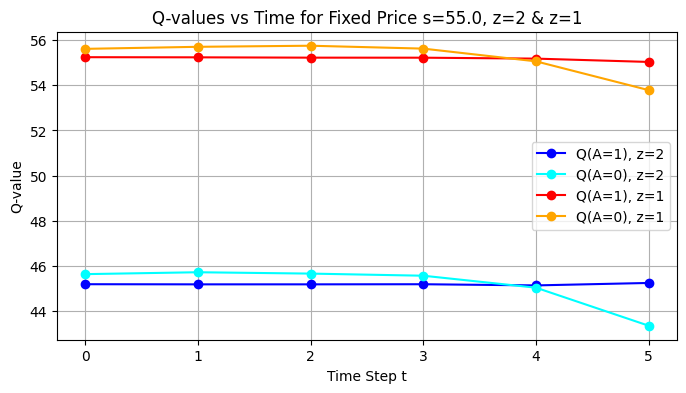

In [76]:
def plot_new_q_values(agent, state):
    t_range = range(agent.env.horizon + 1)
    q_vals_stop_z2, q_vals_cont_z2 = [], []
    q_vals_stop_z1, q_vals_cont_z1 = [], []

    for t in t_range:
        s_tz2 = torch.FloatTensor([state, t, 2]).unsqueeze(0).to(agent.device)
        q_vals_z2 = agent.q_net(s_tz2).detach().cpu().numpy()[0]
        q_vals_stop_z2.append(q_vals_z2[1])
        q_vals_cont_z2.append(q_vals_z2[0])

        s_tz1 = torch.FloatTensor([state, t, 1]).unsqueeze(0).to(agent.device)
        q_vals_z1 = agent.q_net(s_tz1).detach().cpu().numpy()[0]
        q_vals_stop_z1.append(q_vals_z1[1])
        q_vals_cont_z1.append(q_vals_z1[0])

    plt.figure(figsize=(8, 4))
    plt.plot(t_range, q_vals_stop_z2, label='Q(A=1), z=2', marker='o', color='blue')
    plt.plot(t_range, q_vals_cont_z2, label='Q(A=0), z=2', marker='o', color='cyan')
    plt.plot(t_range, q_vals_stop_z1, label='Q(A=1), z=1', marker='o', color='red')
    plt.plot(t_range, q_vals_cont_z1, label='Q(A=0), z=1', marker='o', color='orange')
    plt.xlabel("Time Step t")
    plt.ylabel("Q-value")
    plt.title(f"Q-values vs Time for Fixed Price s={state}, z=2 & z=1")
    plt.legend()
    plt.grid(True)
    plt.show()

plot_new_q_values(agent_disc, state=55.0)

- cumulative reward (train+test)
- hardwire q values at t=N and t=0
- more examples

In [79]:
from tqdm import tqdm
class QLearning:
    def __init__(self, env, epsilon=1, gamma=1, episodes=100000, alpha=0.1):
        self.env = env
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.episodes = episodes
        self.actions = [0, 1]  # 0 = Continue, 1 = Stop
        self.start_states = []
        self.ep_rewards = []

        self.Q = np.zeros(
            (self.env.horizon + 1, len(self.env.states), 2, 2)
        )  # time x state x stops_available (1 or 2) x actions
        self.Q_values_history = np.zeros(
            (self.episodes, self.env.horizon + 1, len(self.env.states), 2, 2)
        )
        for t in range(self.env.horizon):
            for s in range(len(self.env.states)):
                for z in [1, 2]:
                    self.Q[t, s, z - 1, 1] = s - (z - 1) * self.env.cost  # Stop

        self.Q[self.env.horizon, :, :, :] = 0  # no values after the last time step

        self.training_regret = []
        self.optimal_policy = None

    def greedy(self, t, s, z):
        max = np.max(self.Q[t, s, z - 1])
        max_actions = np.argwhere(self.Q[t, s, z - 1] == max).flatten()
        if len(max_actions) > 1:
            return np.random.choice(max_actions)
        else:
            return max_actions[0]
        # return np.argmax(self.Q[t, s, z - 1])  # z ∈ {1,2} → index ∈ {0,1}

    def e_greedy(self, t, s, z):
        if np.random.rand() > self.epsilon:
            return self.greedy(t, s, z)
        return np.random.choice(self.actions)

    def reward(self, s, action, z):
        # if action == 0:  # Continue
        #     return -self.env.cost
        
        if action == 0:  # Continue
            return 0
        else:  # Stop
            if z == 2:  # first stop
                return s - self.env.cost
            elif z == 1:  # second stop
                return s
        return 0

    def simulate_episode(self):
        sequence = self.env.generate_sequence()
        self.start_states.append(sequence[0])  # store the first state of the episode
        z = 2  # two stops available initially
        ep_reward = 0
        for t in range(self.env.horizon):
            s = sequence[t]
            a = self.e_greedy(t, s, z)

            r = self.reward(s, a, z)
            ep_reward += r

            if t < self.env.horizon - 1:
                next_s = sequence[t + 1]
                next_z = z if a == 0 else z - 1  # if Stop, decrement available stops

                if next_z > 0:
                    next_max_q = np.max(self.Q[t + 1, next_s, next_z - 1])
                else:
                    next_max_q = 0  # no more actions after both stops

                self.Q[t, s, z - 1, a] += self.alpha * (
                    r + self.gamma * next_max_q - self.Q[t, s, z - 1, a]
                )  # number of stops available is z, so z-1 is the index

                if a == 1 and next_z == 0:
                    break  # end after 2nd stop

                z = next_z
            else:
                # last step, no next state
                self.Q[t, s, z - 1, a] += self.alpha * (r - self.Q[t, s, z - 1, a])
                break
        self.ep_rewards.append(ep_reward)
        # self.update_regret(sequence, ep_reward)

    
    
    def update_history(self, episode):
        self.Q_values_history[episode] = self.Q.copy()

    def learn(self):
        for i in tqdm(range(self.episodes), desc="Learning Progress"):
            self.simulate_episode()
            self.update_history(i)
            # self.update_loss()

        self.extract_policy()
        return self.Q, self.Q_values_history

    def extract_policy(self):
        policy = np.zeros((self.env.horizon, len(self.env.states), 2), dtype=int)
        for t in range(self.env.horizon):
            for s in range(len(self.env.states)):
                for z in [1, 2]:
                    policy[t, s, z - 1] = np.argmax(self.Q[t, s, z - 1])
        self.optimal_policy = policy
        return policy

    def get_values(self):
        V_1 = np.zeros((self.env.horizon + 1, len(self.env.states)))
        V_2 = np.zeros((self.env.horizon + 1, len(self.env.states)))
        for t in range(self.env.horizon + 1):
            for s in range(len(self.env.states)):
                V_1[t, s] = max(self.Q[t, s, 0, a] for a in self.actions)
                V_2[t, s] = max(self.Q[t, s, 1, a] for a in self.actions)
        return V_1, V_2

    def get_regret(self, V_2):
        self.training_regret = np.zeros(self.episodes)
        self.testing_regret = np.zeros(self.episodes)
        for episode in range(self.episodes):
            # print(episode)
            self.training_regret[episode] = (
                # np.max(self.Q[0][self.start_states[episode], 1])
                V_2[0][self.start_states[episode]]
                - self.ep_rewards[episode]
            )
            sequence = self.env.generate_sequence()
            start_state = sequence[0]
            z = 2  # two stops available initially
            ep_reward = 0
            for t in range(self.env.horizon):
                s = sequence[t]
                a = self.greedy(t, s, z)

                r = self.reward(s, a, z)
                ep_reward += r

                if t < self.env.horizon - 1:
                    next_s = sequence[t + 1]
                    next_z = z if a == 0 else z - 1  # if Stop, decrement available stops

                    if next_z > 0:
                        next_max_q = np.max(self.Q[t + 1, next_s, next_z - 1])
                    else:
                        next_max_q = 0  # no more actions after both stops

                    if a == 1 and next_z == 0:
                        break  # end after 2nd stop
                    z = next_z
                else:
                    break
            self.testing_regret[episode] = (
                V_2[0][start_state] - ep_reward
            )
            
            
        return self.training_regret, self.testing_regret

    def get_average_rewards(self):
        self.average_rewards = np.zeros(self.episodes)
        average_reward = 0
        for episode in range(self.episodes):
            average_reward += (1 / (episode + 1)) * (
                self.ep_rewards[episode] - average_reward
            )
            self.average_rewards[episode] = average_reward
        return self.average_rewards

Learning Progress:   0%|          | 0/20000 [00:00<?, ?it/s]

Learning Progress: 100%|██████████| 20000/20000 [00:01<00:00, 13132.73it/s]


(<Figure size 1200x600 with 1 Axes>,
 <Axes: title={'center': 'Q-values for State 55 (Value: 55)'}, xlabel='Time Step', ylabel='Q-Value'>)

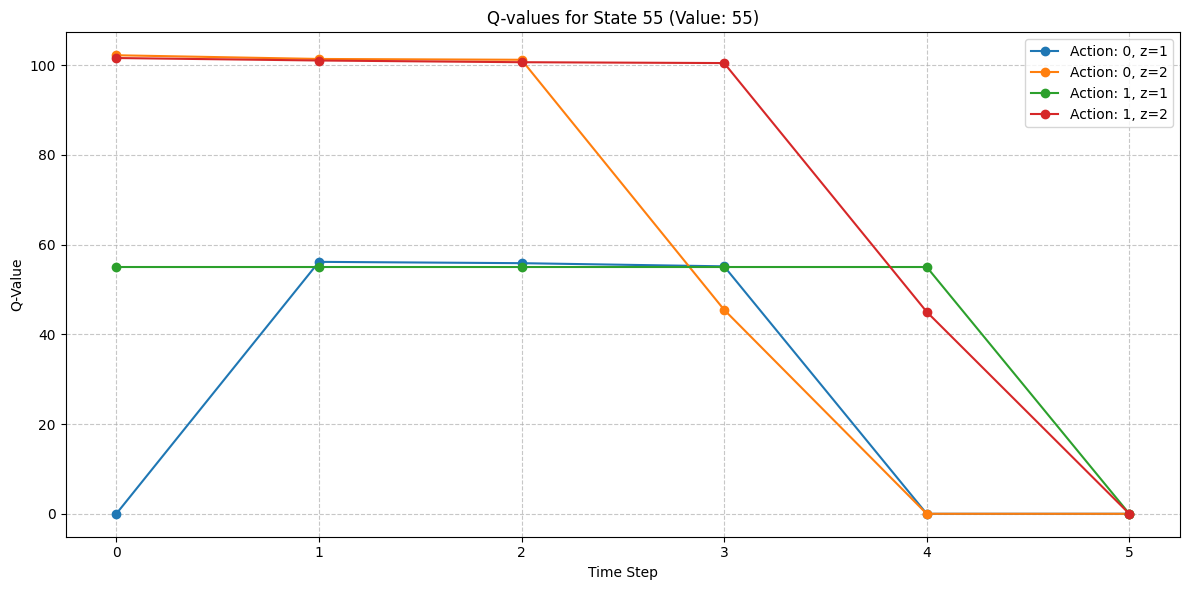

In [80]:
env2 = MarkovianHouseSellingEnv(horizon=5, cost=10, max_offer=100)
Q_agent_2 = QLearning(env2, episodes=20000)
Q_2, history_2 = Q_agent_2.learn()

V_1_2, V_2_2 = Q_agent_2.get_values()

def plot_q_values(Q, state, env, title=None):
    """
    Plot Q-values for a specific state across all time steps, actions, and z-values.
    Each (action, z) pair uses a different color.
    """
    horizon = Q.shape[0]
    action_names = env.actions
    num_actions = len(action_names)

    fig, ax = plt.subplots(figsize=(12, 6))
    time_steps = np.arange(horizon)
    # Use 4 distinct colors for the 4 (action, z) pairs
    colors = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
    line_idx = 0

    for a_idx, action_name in enumerate(action_names):
        for z_index, z_val in enumerate([1, 2]):  # z=1 then z=2
            color = colors[line_idx % len(colors)]
            ax.plot(
                time_steps,
                Q[:, state, z_index, a_idx],
                marker="o",
                label=f"Action: {action_name}, z={z_val}",
                color=color,
            )
            line_idx += 1

    ax.set_xlabel("Time Step")
    ax.set_ylabel("Q-Value")
    ax.set_title(title or f"Q-values for State {state} (Value: {env.states[state]})")
    ax.legend()
    ax.grid(True, linestyle="--", alpha=0.7)
    plt.tight_layout()
    return fig, ax

plot_q_values(Q_2, 55, env2)

In [81]:
def plot_compare_q_values(Q_tabular, agent_dqn, state, env, title=None):
    """
    Plots Q-values from tabular Q-learning and DQN for a given state and both z-values.
    """
    horizon = Q_tabular.shape[0]
    time_steps = np.arange(horizon)
    actions = env.actions

    # Tabular Q-learning
    q_tab_stop_z2 = [Q_tabular[t, state, 1, 1] for t in time_steps]
    q_tab_cont_z2 = [Q_tabular[t, state, 1, 0] for t in time_steps]
    q_tab_stop_z1 = [Q_tabular[t, state, 0, 1] for t in time_steps]
    q_tab_cont_z1 = [Q_tabular[t, state, 0, 0] for t in time_steps]

    # DQN
    q_dqn_stop_z2, q_dqn_cont_z2 = [], []
    q_dqn_stop_z1, q_dqn_cont_z1 = [], []
    for t in time_steps:
        s_tz2 = torch.FloatTensor([state, t, 2]).unsqueeze(0).to(agent_dqn.device)
        q_vals_z2 = agent_dqn.q_net(s_tz2).detach().cpu().numpy()[0]
        q_dqn_stop_z2.append(q_vals_z2[1])
        q_dqn_cont_z2.append(q_vals_z2[0])

        s_tz1 = torch.FloatTensor([state, t, 1]).unsqueeze(0).to(agent_dqn.device)
        q_vals_z1 = agent_dqn.q_net(s_tz1).detach().cpu().numpy()[0]
        q_dqn_stop_z1.append(q_vals_z1[1])
        q_dqn_cont_z1.append(q_vals_z1[0])

    plt.figure(figsize=(12, 6))
    # Tabular
    plt.plot(time_steps, q_tab_stop_z2, label='Tabular Q(A=1), z=2', color='blue', linestyle='-')
    plt.plot(time_steps, q_tab_cont_z2, label='Tabular Q(A=0), z=2', color='cyan', linestyle='-')
    plt.plot(time_steps, q_tab_stop_z1, label='Tabular Q(A=1), z=1', color='red', linestyle='-')
    plt.plot(time_steps, q_tab_cont_z1, label='Tabular Q(A=0), z=1', color='orange', linestyle='-')
    # DQN
    plt.plot(time_steps, q_dqn_stop_z2, label='DQN Q(A=1), z=2', color='blue', linestyle='--')
    plt.plot(time_steps, q_dqn_cont_z2, label='DQN Q(A=0), z=2', color='cyan', linestyle='--')
    plt.plot(time_steps, q_dqn_stop_z1, label='DQN Q(A=1), z=1', color='red', linestyle='--')
    plt.plot(time_steps, q_dqn_cont_z1, label='DQN Q(A=0), z=1', color='orange', linestyle='--')

    plt.xlabel("Time Step t")
    plt.ylabel("Q-value")
    plt.title(title or f"Q-values vs Time for State={state} (Value={env.states[state]})")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


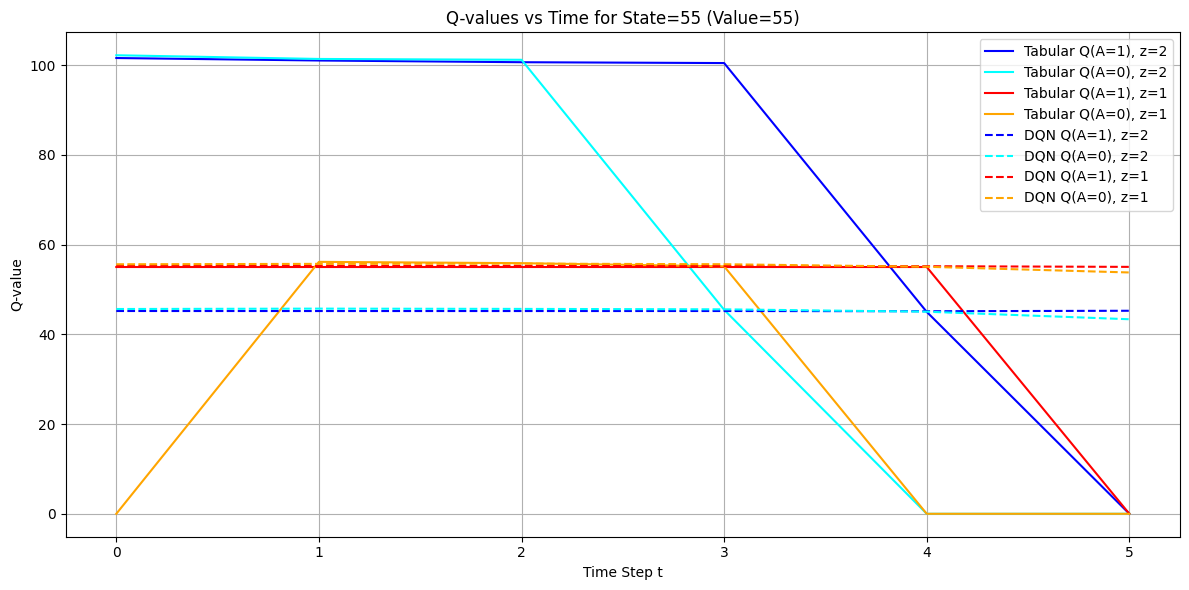

In [83]:
# Example usage:
plot_compare_q_values(Q_2, agent_disc, state=55, env=env2)